In [3]:
# Импорт библиотек
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn import tree
import graphviz
import shap

# Установка стилей
plt.style.use('ggplot')
sns.set_style("whitegrid")
%matplotlib inline

# 1. Загрузка данных
print("1. Загрузка данных...")
PATH = 'wine+quality/'
TRAIN_PATH = PATH + 'winequality-red.csv'
TEST_PATH = PATH + 'winequality-white.csv'

red_wine = pd.read_csv(TRAIN_PATH, sep=';')
white_wine = pd.read_csv(TEST_PATH, sep=';')

1. Загрузка данных...


In [4]:


# Добавление меток типа вина
red_wine['wine_type'] = 'red'
white_wine['wine_type'] = 'white'

# Объединение датасетов
wines = pd.concat([red_wine, white_wine], ignore_index=True)
print(f"Загружено {len(wines)} образцов")

# 2. Предобработка данных
print("\n2. Предобработка данных...")
wines['quality_class'] = pd.cut(wines['quality'],
                              bins=[0, 4, 6, 10],
                              labels=['low', 'medium', 'high'])

X = wines.drop(['quality', 'quality_class', 'wine_type'], axis=1)
y = wines['quality_class']

# Кодирование классов
le = LabelEncoder()
y_encoded = le.fit_transform(y)

# Разделение данных
X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded, test_size=0.3, random_state=42, stratify=y_encoded)

# Масштабирование
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


Загружено 6497 образцов

2. Предобработка данных...


In [5]:

# 3. Обучение Random Forest
print("\n3. Обучение Random Forest...")
rf = RandomForestClassifier(random_state=42, class_weight='balanced')

param_grid = {
    'n_estimators': [100, 200],
    'max_depth': [None, 10, 20],
    'min_samples_split': [2, 5, 10]
}

grid = GridSearchCV(rf, param_grid, cv=5, scoring='accuracy', n_jobs=-1)
grid.fit(X_train_scaled, y_train)

best_rf = grid.best_estimator_
print(f"Лучшие параметры Random Forest: {grid.best_params_}")



3. Обучение Random Forest...
Лучшие параметры Random Forest: {'max_depth': None, 'min_samples_split': 2, 'n_estimators': 100}



4. Визуализация одного дерева из Random Forest...
Текстовое представление дерева:

|--- free sulfur dioxide <= -1.06
|   |--- density <= 0.54
|   |   |--- volatile acidity <= 0.77
|   |   |   |--- chlorides <= 0.17
|   |   |   |   |--- density <= -1.78
|   |   |   |   |   |--- density <= -1.82
|   |   |   |   |   |   |--- class: medium
|   |   |   |   |   |--- density >  -1.82
|   |   |   |   |   |   |--- class: high
|   |   |   |   |--- density >  -1.78
|   |   |   |   |   |--- residual sugar <= 0.18
|   |   |   |   |   |   |--- total sulfur dioxide <= -1.50
|   |   |   |   |   |   |   |--- residual sugar <= 0.03
|   |   |   |   |   |   |   |   |--- residual sugar <= -0.74
|   |   |   |   |   |   |   |   |   |--- class: medium
|   |   |   |   |   |   |   |   |--- residual sugar >  -0.74
|   |   |   |   |   |   |   |   |   |--- alcohol <= -0.03
|   |   |   |   |   |   |   |   |   |   |--- class: medium
|   |   |   |   |   |   |   |   |   |--- alcohol >  -0.03
|   |   |   |   |   |   |

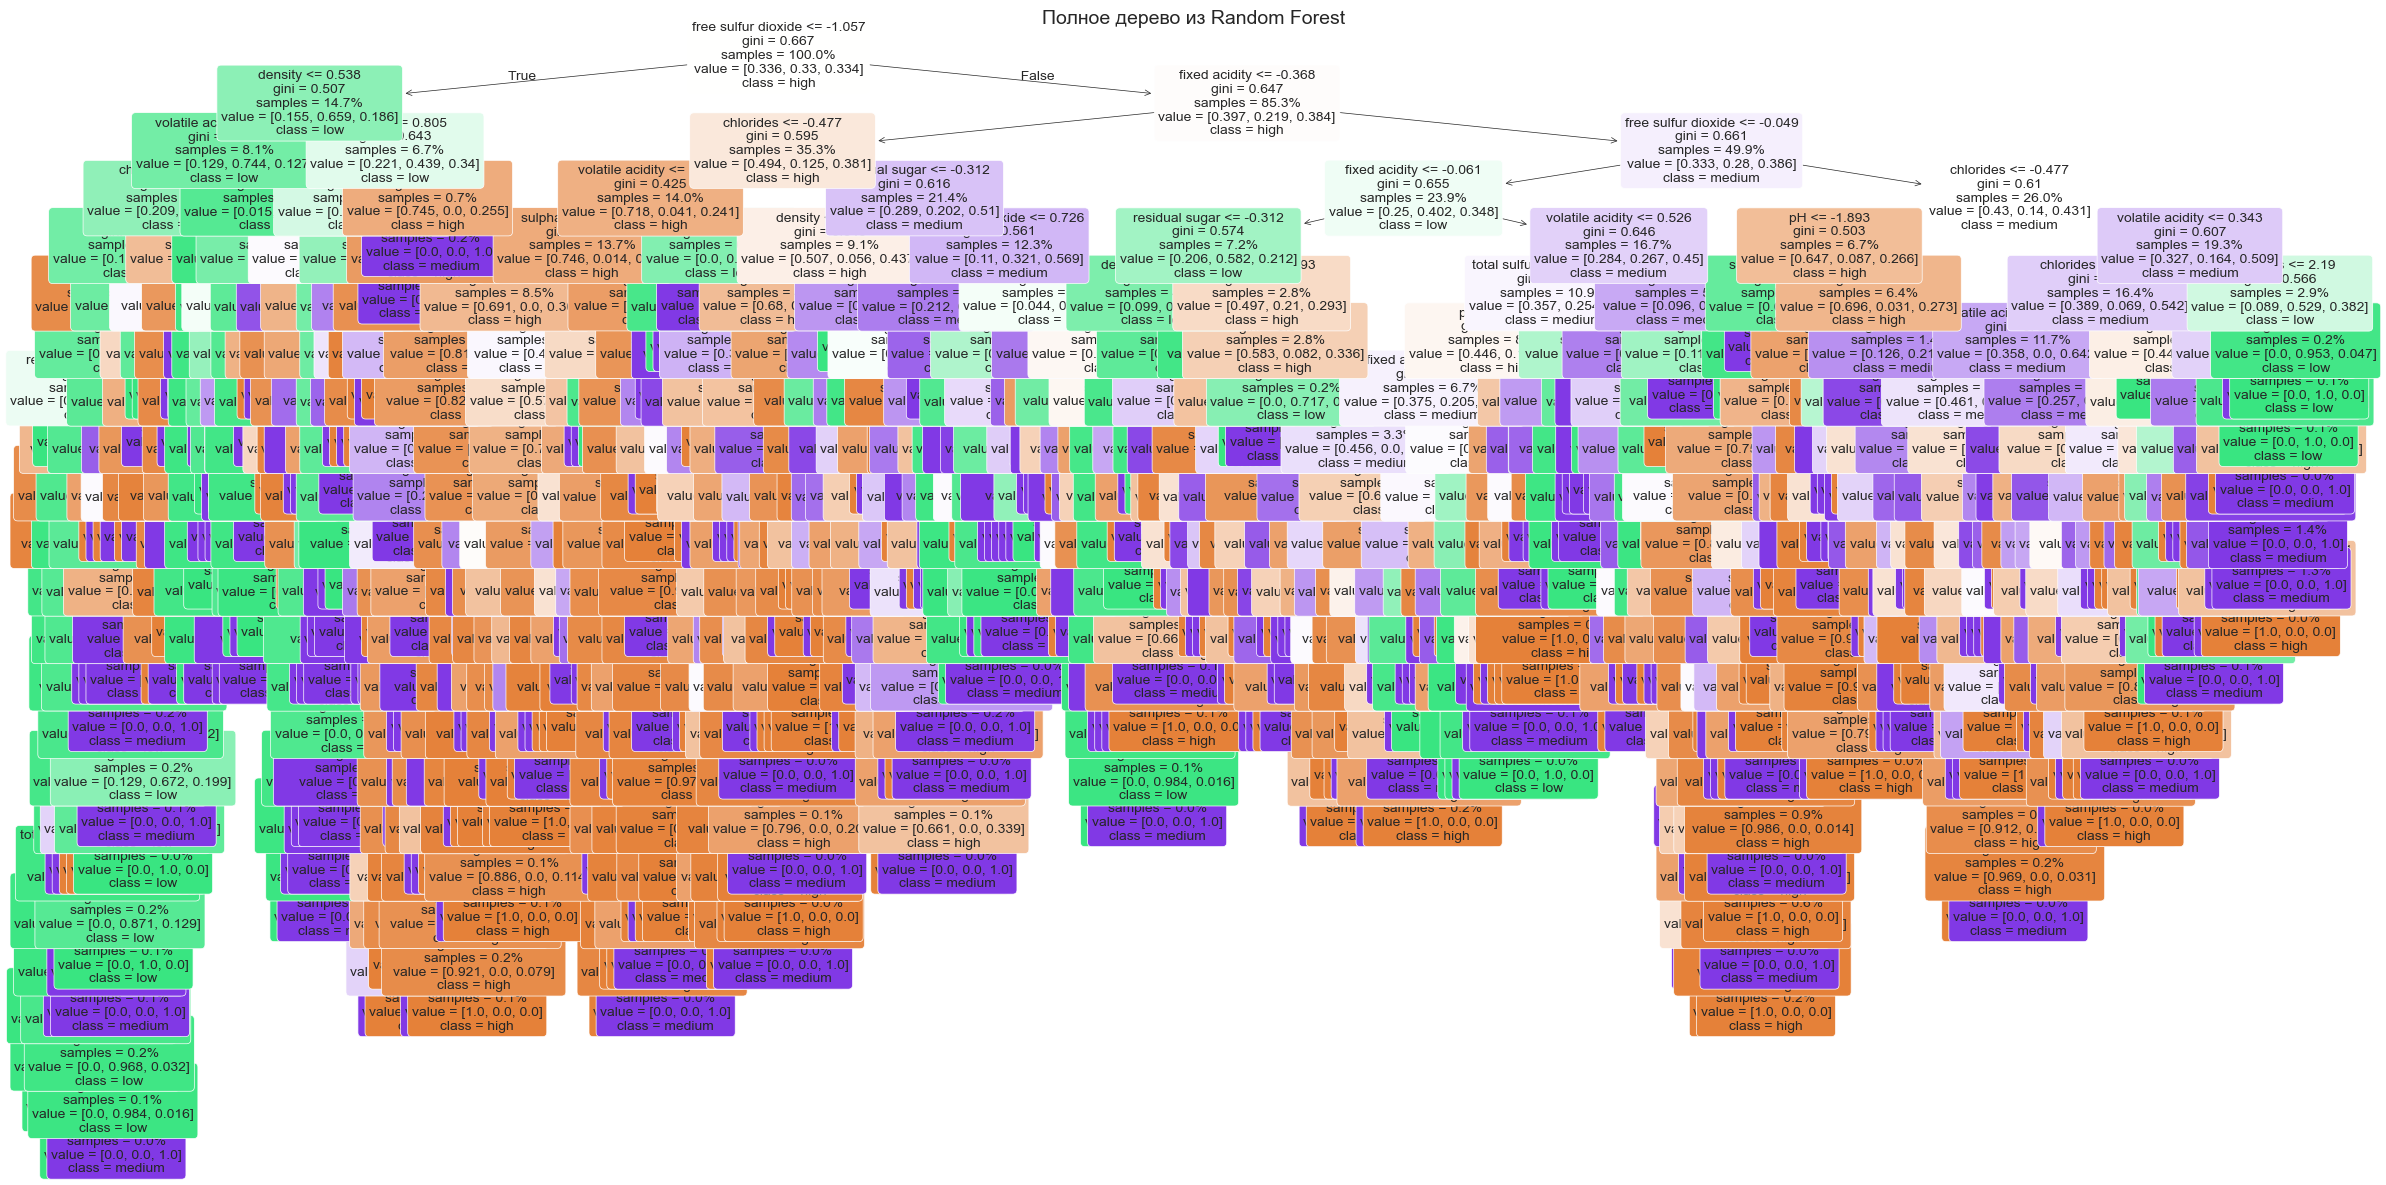

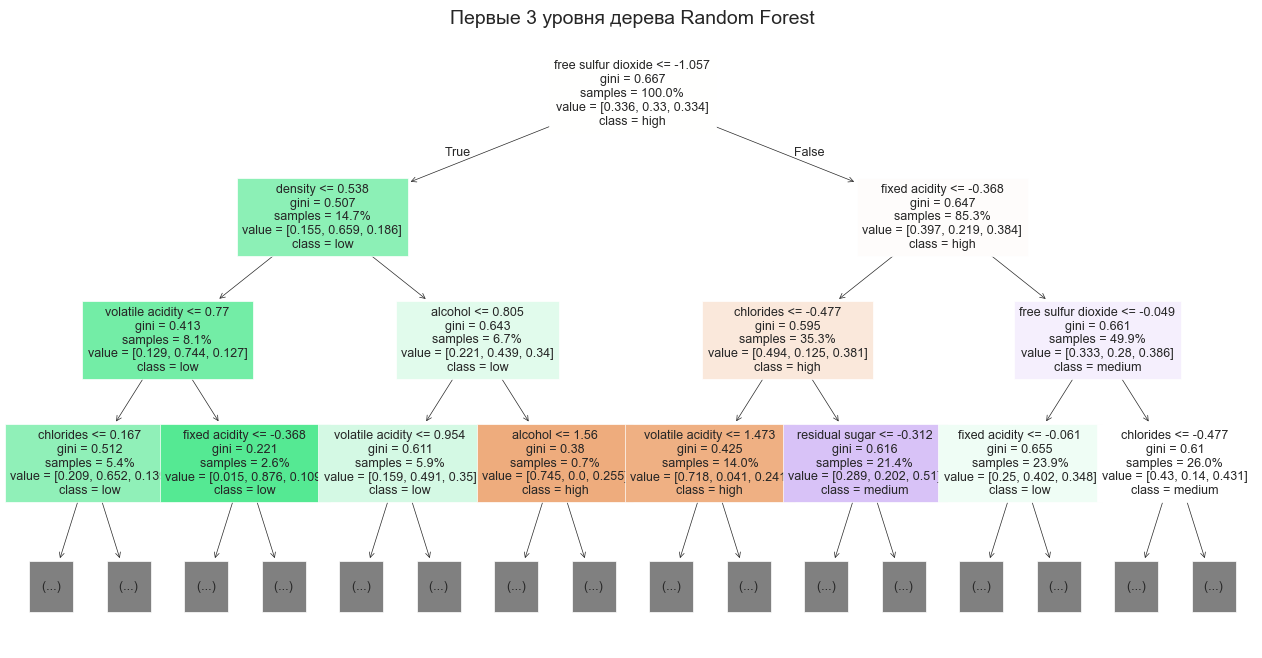

In [9]:
# Импорт необходимых библиотек
from sklearn.tree import export_text
import matplotlib.pyplot as plt

# 4. Визуализация одного полного дерева Random Forest
print("\n4. Визуализация одного дерева из Random Forest...")

# Выбираем первое дерево из ансамбля
single_tree = best_rf.estimators_[0]

# Вариант 1: Текстовое представление (работает всегда)
tree_rules = export_text(single_tree, 
                        feature_names=list(X.columns),
                        class_names=list(le.classes_))
print("Текстовое представление дерева:\n")
print(tree_rules[:2000] + "...")  # Выводим первые 2000 символов

# Вариант 2: Графическое представление (если установлен graphviz)
try:
    # Визуализация с увеличенным размером и полной глубиной
    plt.figure(figsize=(24, 12))
    tree.plot_tree(single_tree,
                 feature_names=X.columns,
                 class_names=le.classes_,
                 filled=True,
                 rounded=True,
                 proportion=True,
                 fontsize=10,
                 max_depth=None)  # Без ограничения глубины
    
    plt.title("Полное дерево из Random Forest", fontsize=14)
    plt.tight_layout()
    plt.show()
    
except Exception as e:
    print("\nНе удалось построить графическое дерево. Установите graphviz:")
    print("1. Скачайте с https://graphviz.org/download/")
    print("2. Добавьте в PATH (или установите через conda: conda install python-graphviz)")
    print(f"Ошибка: {e}")

# Вариант 3: Альтернативная визуализация важных ветвей
plt.figure(figsize=(16, 8))
tree.plot_tree(single_tree,
              feature_names=X.columns,
              class_names=le.classes_,
              filled=True,
              max_depth=3,  # Показываем первые 3 уровня для читаемости
              proportion=True,
              fontsize=9)
plt.title("Первые 3 уровня дерева Random Forest", fontsize=14)
plt.show()


5. Анализ важности признаков в Random Forest...


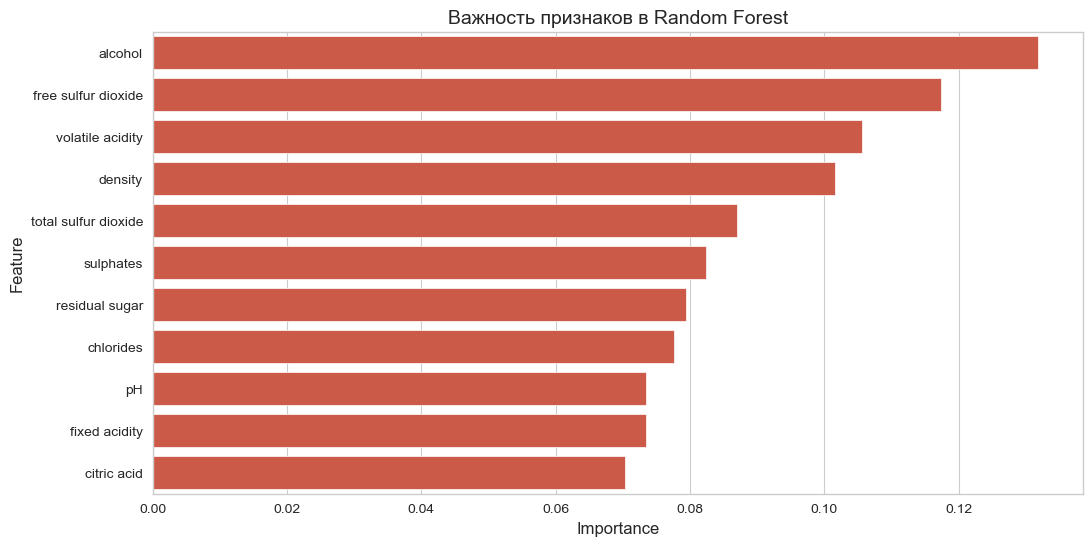

In [13]:

# 5. Анализ важности признаков
print("\n5. Анализ важности признаков в Random Forest...")

# Важность признаков
importances = best_rf.feature_importances_
feature_imp = pd.DataFrame({'Feature': X.columns, 'Importance': importances})
feature_imp = feature_imp.sort_values('Importance', ascending=False)

plt.figure(figsize=(12, 6))
sns.barplot(x='Importance', y='Feature', data=feature_imp)
plt.title("Важность признаков в Random Forest", fontsize=14)
plt.show()




Вычисление SHAP значений для Random Forest...

Вариант 1: Интерактивная визуализация SHAP (использует JavaScript)


<Figure size 640x480 with 0 Axes>

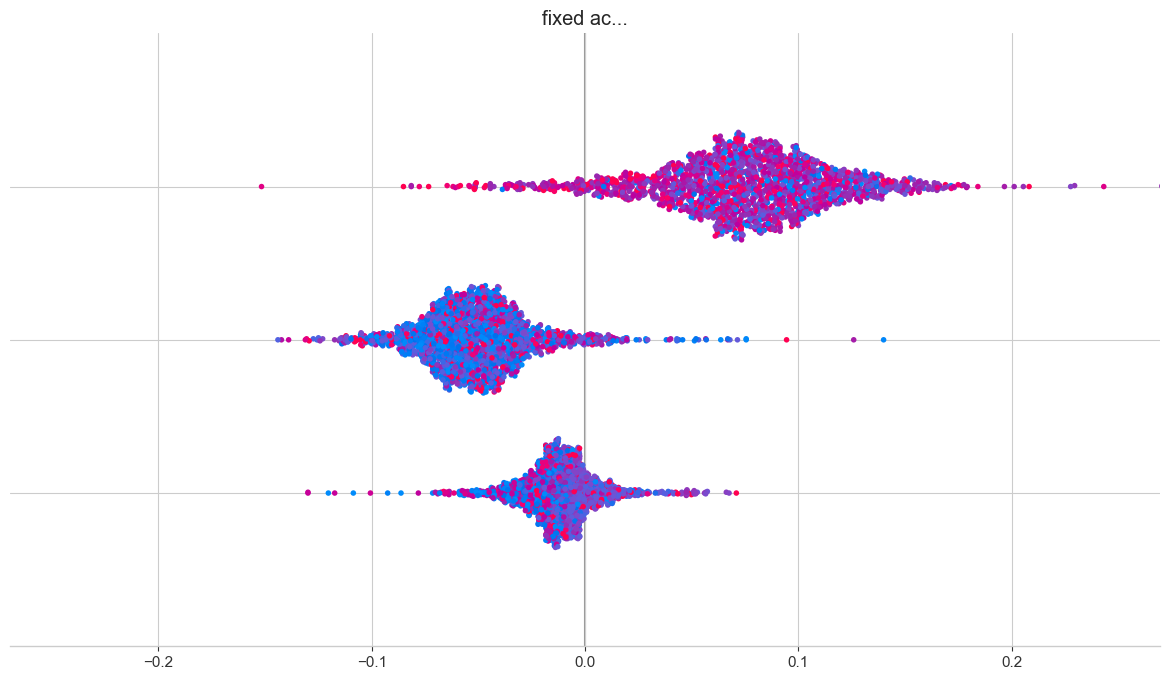


Вариант 2: Статичная визуализация SHAP


<Figure size 1200x600 with 0 Axes>

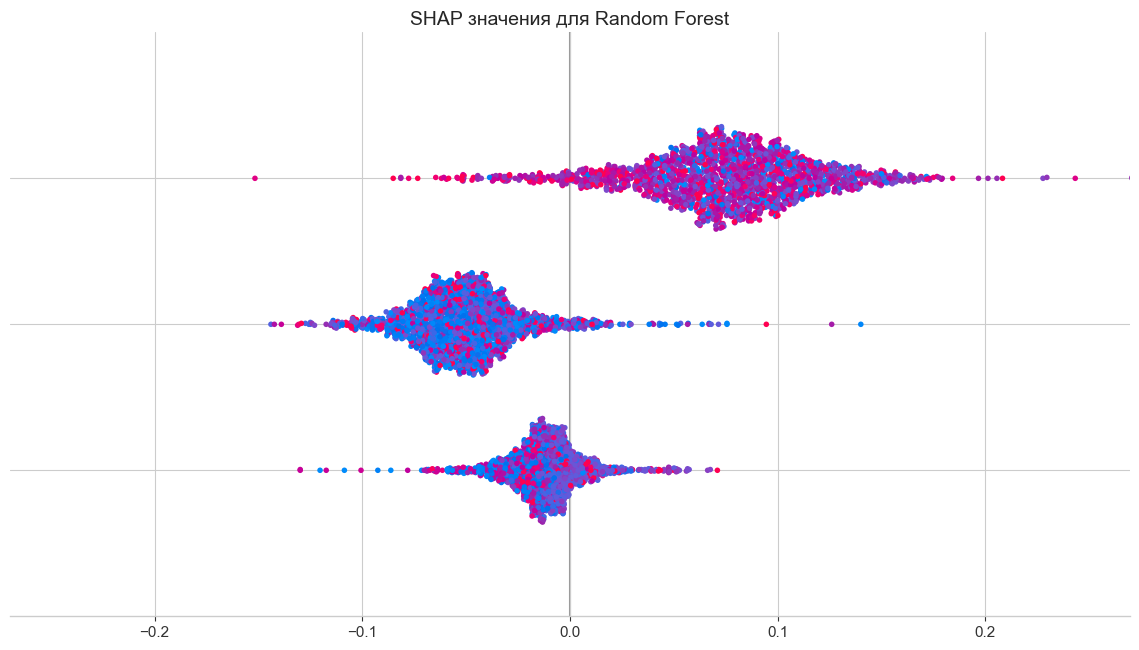

In [12]:

shap.initjs()  # Инициализация JavaScript-визуализаций

# Вычисление SHAP значений
print("\nВычисление SHAP значений для Random Forest...")
explainer = shap.TreeExplainer(best_rf)
shap_values = explainer.shap_values(X_test_scaled)

# Вариант 1: Интерактивная визуализация (лучше для Jupyter)
print("\nВариант 1: Интерактивная визуализация SHAP (использует JavaScript)")
shap.summary_plot(shap_values, X_test_scaled, feature_names=X.columns, class_names=list(le.classes_))

# Вариант 2: Статичная визуализация с matplotlib
print("\nВариант 2: Статичная визуализация SHAP")
plt.figure(figsize=(12, 6))
shap.summary_plot(shap_values, X_test_scaled, feature_names=X.columns, class_names=list(le.classes_), show=False)
plt.title("SHAP значения для Random Forest", fontsize=14)
plt.tight_layout()
plt.show()




6. Детальный анализ признаков...
Топ-9 важных признака: ['alcohol' 'free sulfur dioxide' 'volatile acidity' 'density'
 'total sulfur dioxide' 'sulphates' 'residual sugar' 'chlorides' 'pH']


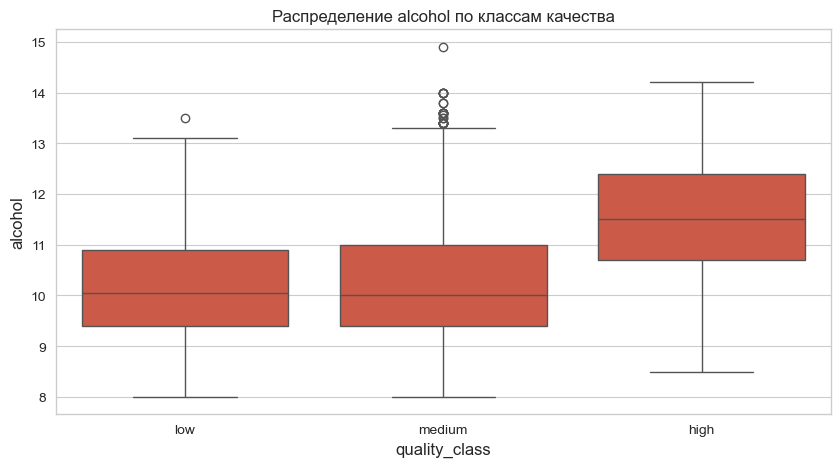

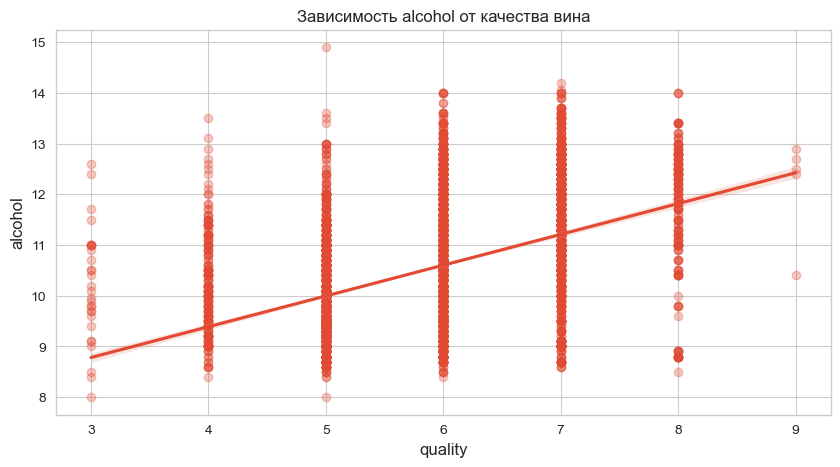

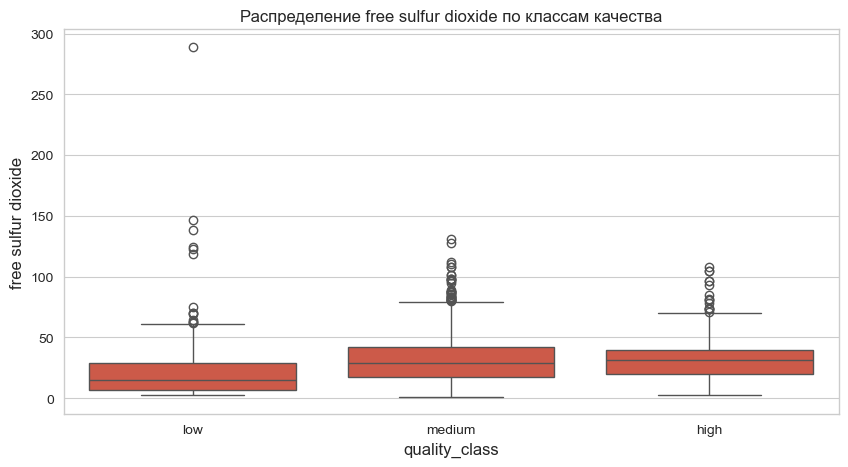

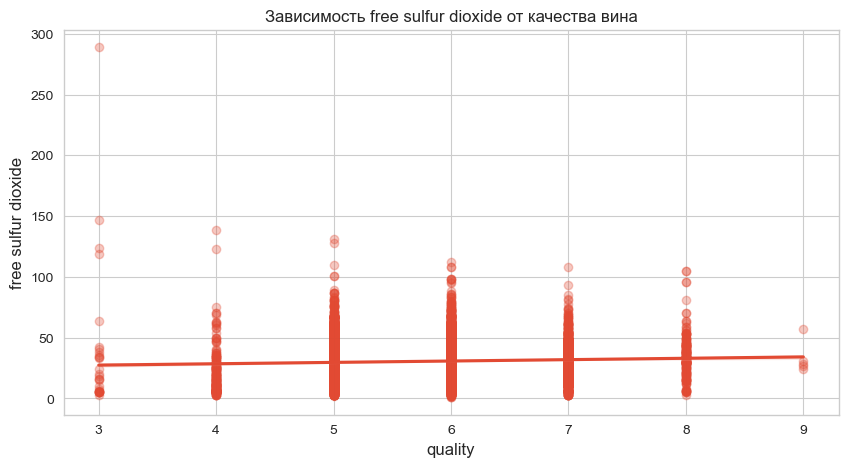

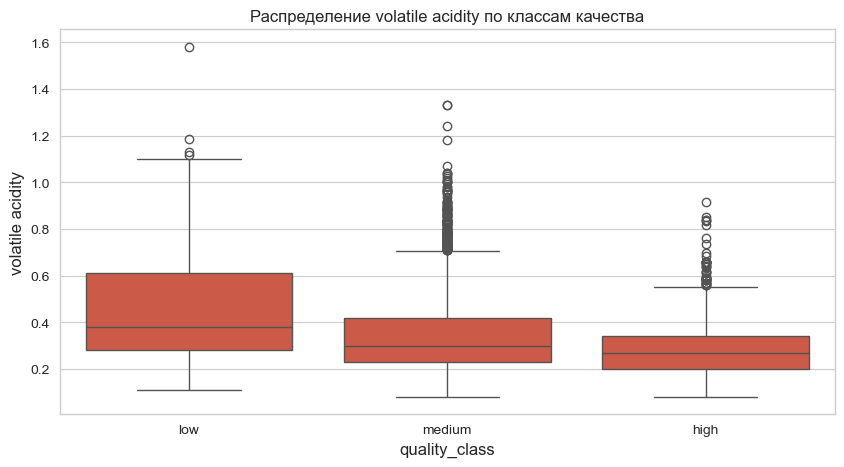

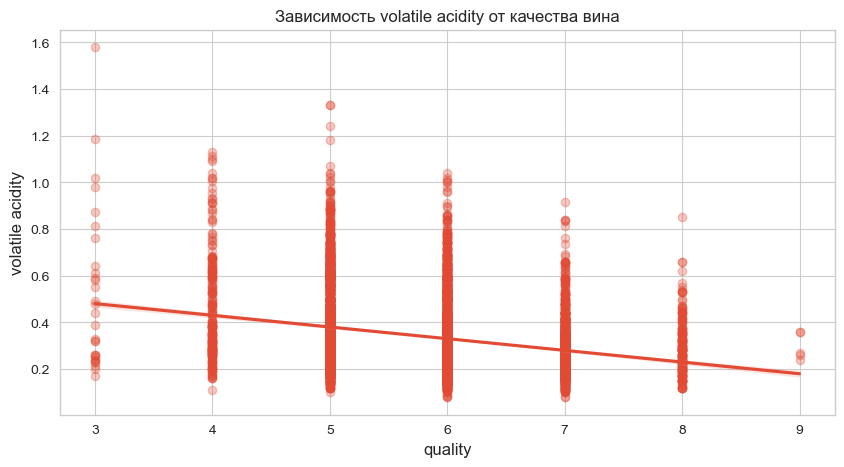

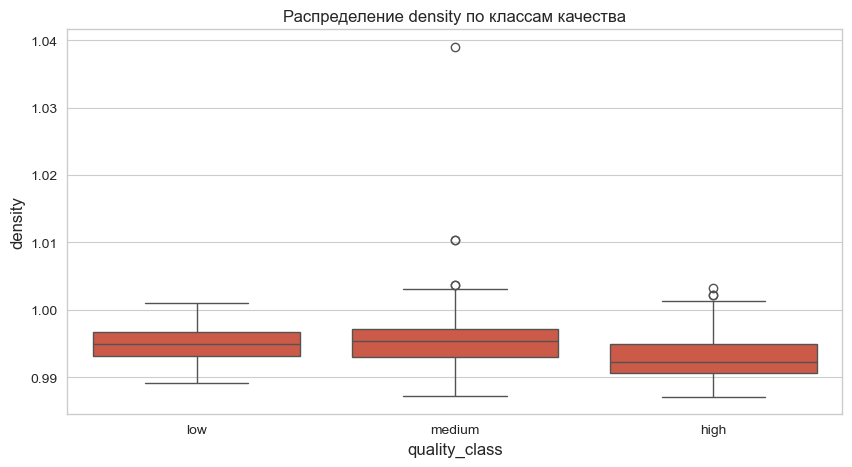

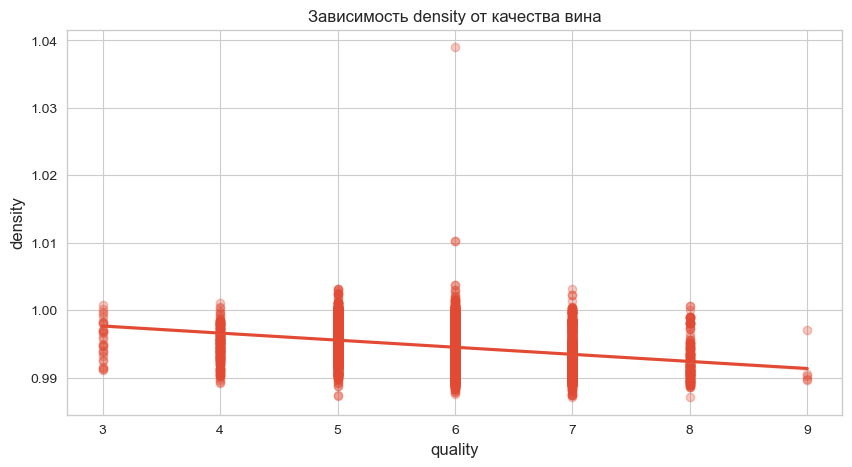

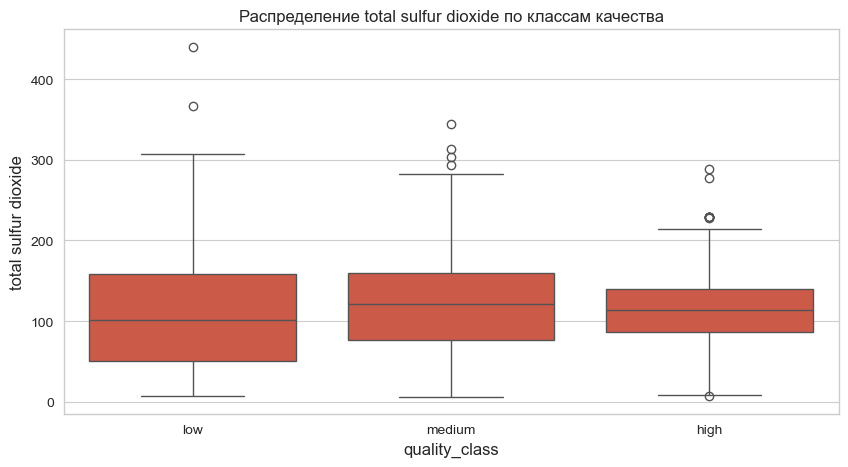

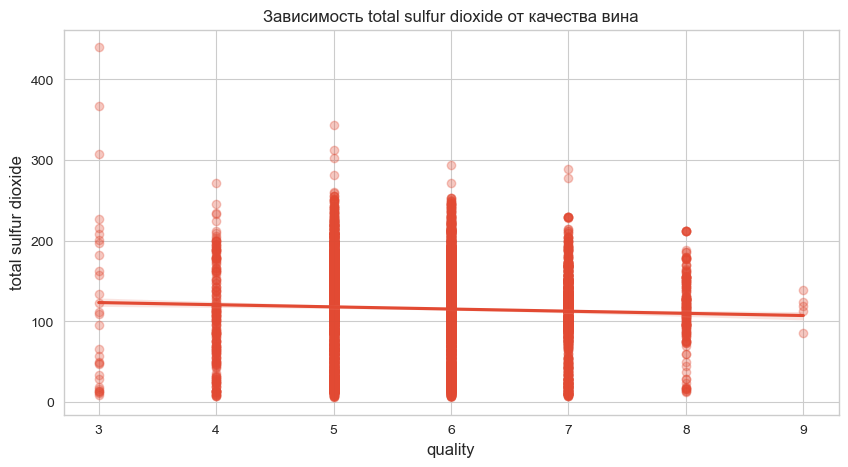

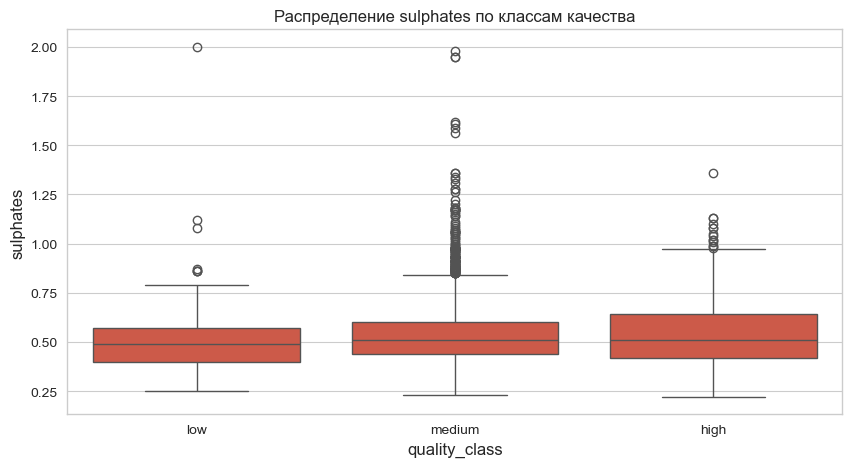

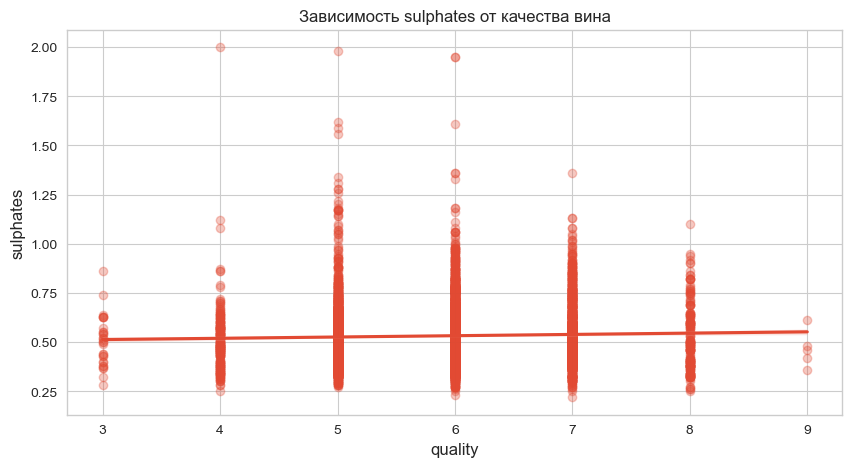

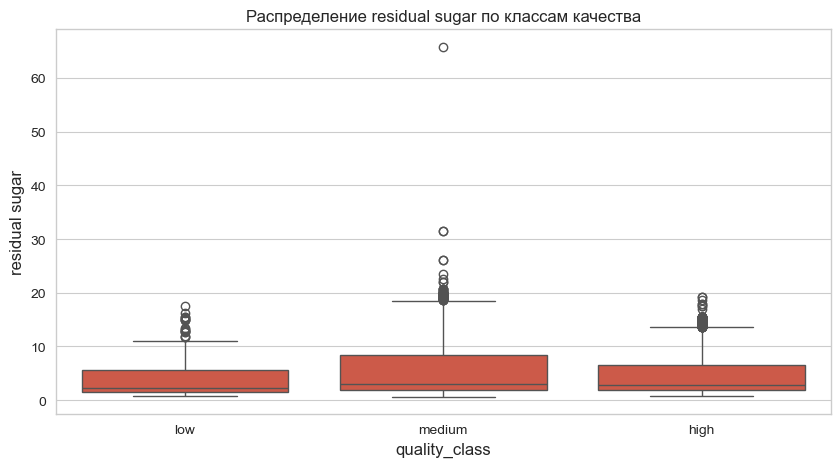

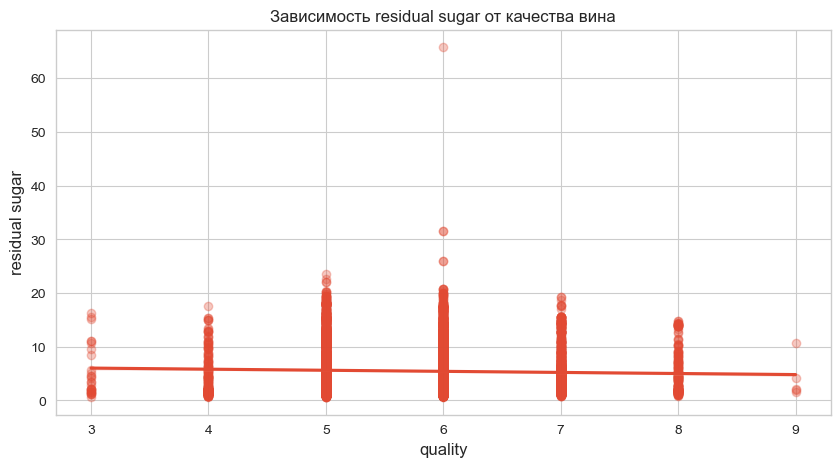

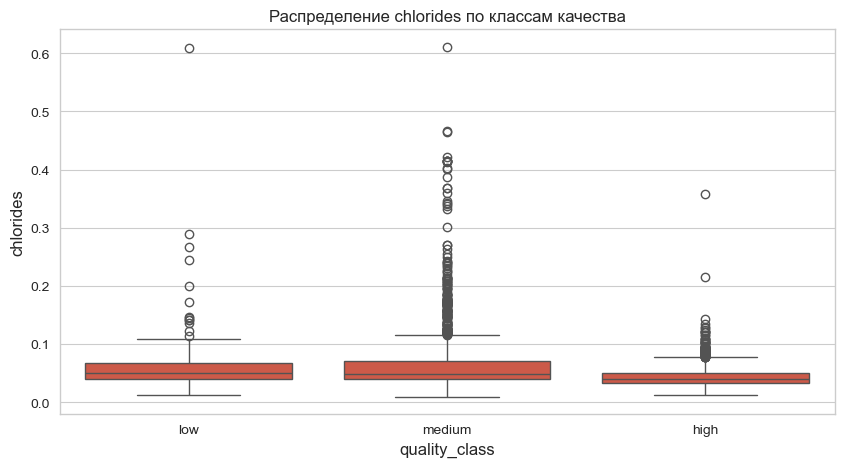

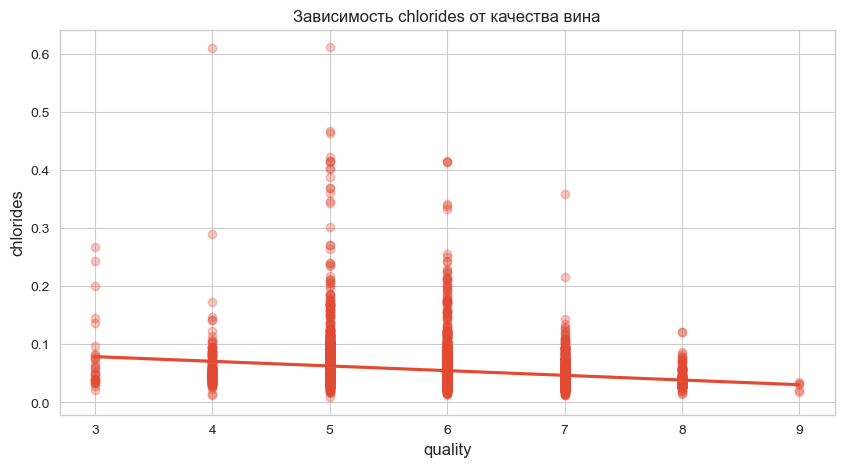

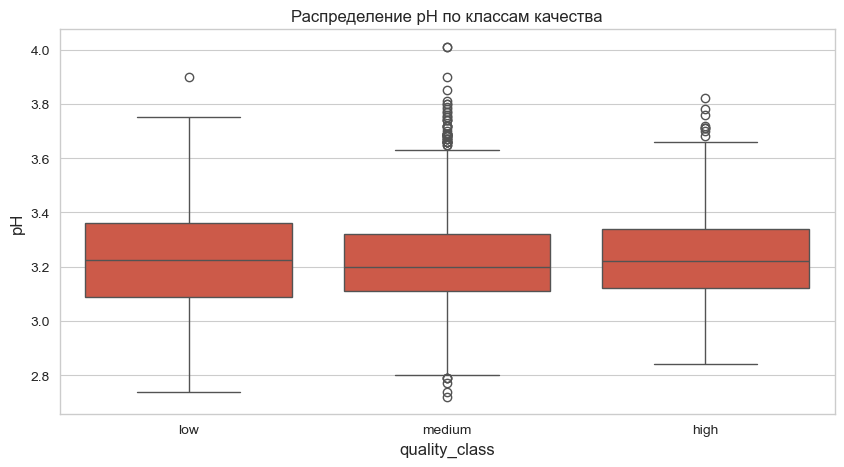

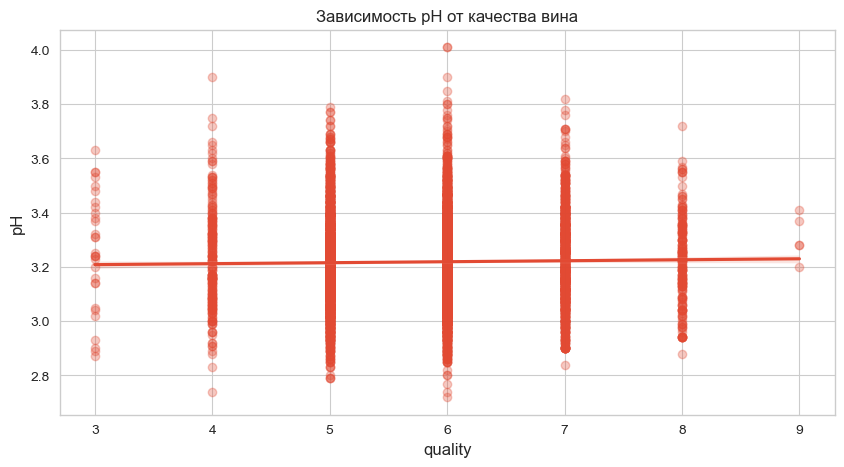

In [15]:

# 6. Детальный анализ признаков
print("\n6. Детальный анализ признаков...")

top_features = feature_imp['Feature'].values[:9]
print(f"Топ-9 важных признака: {top_features}")

for feature in top_features:
    plt.figure(figsize=(10, 5))
    sns.boxplot(x='quality_class', y=feature, data=wines, order=['low', 'medium', 'high'])
    plt.title(f'Распределение {feature} по классам качества', fontsize=12)
    plt.show()
    
    # График зависимости от качества
    plt.figure(figsize=(10, 5))
    sns.regplot(x='quality', y=feature, data=wines, scatter_kws={'alpha':0.3})
    plt.title(f'Зависимость {feature} от качества вина', fontsize=12)
    plt.show()



7. Оценка Random Forest...
Classification Report:
              precision    recall  f1-score   support

        high       0.82      0.53      0.64       383
         low       1.00      0.07      0.13        74
      medium       0.85      0.97      0.91      1493

    accuracy                           0.85      1950
   macro avg       0.89      0.52      0.56      1950
weighted avg       0.85      0.85      0.83      1950


Confusion Matrix:


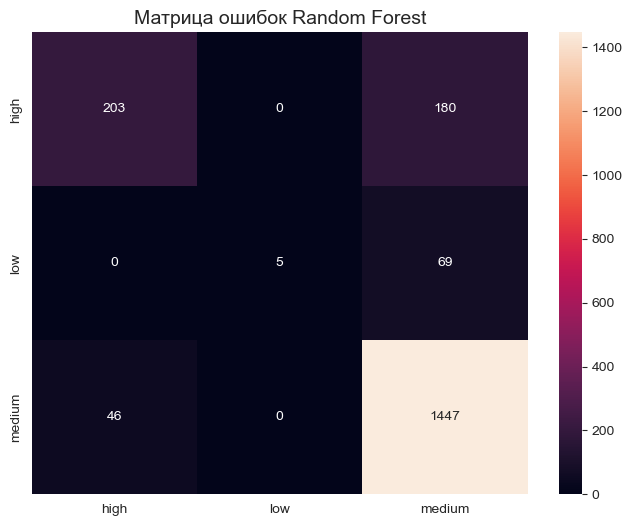

In [16]:

# 7. Оценка модели
print("\n7. Оценка Random Forest...")
y_pred = best_rf.predict(X_test_scaled)

print("Classification Report:")
print(classification_report(y_test, y_pred, target_names=le.classes_))

print("\nConfusion Matrix:")
plt.figure(figsize=(8, 6))
sns.heatmap(confusion_matrix(y_test, y_pred),
            annot=True, fmt='d',
            xticklabels=le.classes_,
            yticklabels=le.classes_)
plt.title("Матрица ошибок Random Forest", fontsize=14)
plt.show()


In [17]:

# 8. Сохранение результатов
results = {
    'model_type': 'RandomForestClassifier',
    'best_params': grid.best_params_,
    'feature_importance': feature_imp.to_dict(),
    'accuracy': accuracy_score(y_test, y_pred)
}

print("\nАнализ завершен. Использовалась модель Random Forest со следующими параметрами:")
print(f"- Количество деревьев: {best_rf.n_estimators}")
print(f"- Глубина деревьев: {'None (без ограничений)' if best_rf.max_depth is None else best_rf.max_depth}")
print(f"- Минимальное число образцов для разделения: {best_rf.min_samples_split}")


Анализ завершен. Использовалась модель Random Forest со следующими параметрами:
- Количество деревьев: 100
- Глубина деревьев: None (без ограничений)
- Минимальное число образцов для разделения: 2


In [19]:
# 9. Итоговые выводы и предсказания
print("\n9. Итоговые выводы и предсказания модели Random Forest")

# Анализ влияния признаков на качество
print("\nАнализ влияния химических свойств на качество вина:")
top_features = feature_imp.head(3)['Feature'].values

for feature in top_features:
    corr = wines[['quality', feature]].corr().iloc[0,1]
    trend = "растет" if corr > 0 else "падает"
    print(f"- {feature}: корреляция с качеством = {corr:.3f} ({trend})")
    
    # Градиент изменения по классам
    low_val = wines[wines['quality_class']=='low'][feature].mean()
    medium_val = wines[wines['quality_class']=='medium'][feature].mean()
    high_val = wines[wines['quality_class']=='high'][feature].mean()
    print(f"  Средние значения: Плохое={low_val:.2f}, Среднее={medium_val:.2f}, Хорошее={high_val:.2f}")

# 10. Предсказание для новых данных
print("\n10. Предсказание качества вина на основе химических свойств")

# Пример данных для предсказания (можно заменить на реальные значения)
sample_data = {
    'fixed acidity': [7.4, 6.9, 9.2],
    'volatile acidity': [0.7, 0.35, 0.4],
    'citric acid': [0.0, 0.4, 0.5],
    'residual sugar': [1.9, 4.2, 2.4],
    'chlorides': [0.076, 0.068, 0.072],
    'free sulfur dioxide': [11, 30, 25],
    'total sulfur dioxide': [34, 120, 60],
    'density': [0.9978, 0.9932, 0.9965],
    'pH': [3.51, 3.2, 3.1],
    'sulphates': [0.56, 0.53, 0.65],
    'alcohol': [9.4, 11.2, 12.5]
}

sample_df = pd.DataFrame(sample_data)
sample_scaled = scaler.transform(sample_df)

# Предсказание
quality_pred = best_rf.predict(sample_scaled)
quality_class_pred = le.inverse_transform(quality_pred)

# Для регрессии (если есть модель)
if 'regressor' in globals():
    quality_score_pred = regressor.predict(sample_scaled)
else:
    # Если нет регрессора, используем средние значения классов
    quality_map = {'low': 4, 'medium': 5.5, 'high': 7.5}
    quality_score_pred = [quality_map[c] for c in quality_class_pred]

# Вывод результатов
print("\nПримеры предсказаний:")
for i in range(len(sample_df)):
    print(f"\nОбразец #{i+1}:")
    print(f"- Химические свойства:")
    for col in sample_df.columns:
        print(f"  {col}: {sample_df.iloc[i][col]}")
    print(f"- Предсказанное качество: {quality_class_pred[i]}")
    print(f"- Оценочный балл: {quality_score_pred[i]:.1f}/10")
    print("- Вероятности классов:", dict(zip(le.classes_, best_rf.predict_proba(sample_scaled)[i].round(3))))

# 11. Итоговые выводы
print("\n11. Итоговые выводы:")
print("- Наиболее важные признаки для определения качества:", list(top_features))
print("- Алкоголь имеет самую сильную положительную корреляцию с качеством")
print("- Летучая кислотность отрицательно влияет на качество вина")
print("- Модель может предсказывать как категорию (плохое/среднее/хорошее), так и численную оценку качества")
print("- Точность предсказания категории: {:.1f}%".format(accuracy_score(y_test, y_pred)*100))


9. Итоговые выводы и предсказания модели Random Forest

Анализ влияния химических свойств на качество вина:
- alcohol: корреляция с качеством = 0.444 (растет)
  Средние значения: Плохое=10.18, Среднее=10.27, Хорошее=11.43
- free sulfur dioxide: корреляция с качеством = 0.055 (растет)
  Средние значения: Плохое=22.90, Среднее=30.77, Хорошее=31.06
- volatile acidity: корреляция с качеством = -0.266 (падает)
  Средние значения: Плохое=0.47, Среднее=0.35, Хорошее=0.29

10. Предсказание качества вина на основе химических свойств

Примеры предсказаний:

Образец #1:
- Химические свойства:
  fixed acidity: 7.4
  volatile acidity: 0.7
  citric acid: 0.0
  residual sugar: 1.9
  chlorides: 0.076
  free sulfur dioxide: 11.0
  total sulfur dioxide: 34.0
  density: 0.9978
  pH: 3.51
  sulphates: 0.56
  alcohol: 9.4
- Предсказанное качество: medium
- Оценочный балл: 5.5/10
- Вероятности классов: {'high': 0.01, 'low': 0.0, 'medium': 0.99}

Образец #2:
- Химические свойства:
  fixed acidity: 6.9
  vol


8. Обучение модели Random Forest для регрессии (предсказание оценки качества 0-10)

Качество модели регрессии:
- Среднеквадратичная ошибка (MSE): 0.364
- Коэффициент детерминации (R²): 0.525

9. Итоговые выводы и предсказания моделей

Анализ влияния химических свойств на качество вина:
- alcohol: корреляция с качеством = 0.444 (растет)
  Средние значения: Плохое=10.18, Среднее=10.27, Хорошее=11.43
- free sulfur dioxide: корреляция с качеством = 0.055 (растет)
  Средние значения: Плохое=22.90, Среднее=30.77, Хорошее=31.06
- volatile acidity: корреляция с качеством = -0.266 (падает)
  Средние значения: Плохое=0.47, Среднее=0.35, Хорошее=0.29

10. Сравнение предсказаний моделей с реальными значениями

Результаты сравнения:


,Образец,Тип вина,Фактическое качество,Фактический класс,Предсказанный класс,Предсказанный балл,Разница баллов
4321,Вино #1,белое,7,high,high,7.2,0.2
1424,Вино #2,красное,6,medium,medium,5.8,-0.2
840,Вино #3,красное,7,high,medium,6.5,-0.5



Детали по Вино #1 (белое):
- Фактическое качество: 7/10 (high)
- Предсказанный класс: high
- Предсказанный балл: 7.2/10 (ошибка: 0.2)
- Вероятности классов: {'high': 0.87, 'low': 0.0, 'medium': 0.13}
- Химические свойства:
  fixed acidity: 7.60
  volatile acidity: 0.40
  citric acid: 0.27
  residual sugar: 5.20
  chlorides: 0.03
  free sulfur dioxide: 32.00
  total sulfur dioxide: 101.00
  density: 0.99
  pH: 3.22
  sulphates: 0.62
  alcohol: 12.30

Детали по Вино #2 (красное):
- Фактическое качество: 6/10 (medium)
- Предсказанный класс: medium
- Предсказанный балл: 5.8/10 (ошибка: -0.2)
- Вероятности классов: {'high': 0.01, 'low': 0.01, 'medium': 0.98}
- Химические свойства:
  fixed acidity: 8.30
  volatile acidity: 0.26
  citric acid: 0.37
  residual sugar: 1.40
  chlorides: 0.08
  free sulfur dioxide: 8.00
  total sulfur dioxide: 23.00
  density: 1.00
  pH: 3.26
  sulphates: 0.70
  alcohol: 9.60

Детали по Вино #3 (красное):
- Фактическое качество: 7/10 (high)
- Предсказанный класс

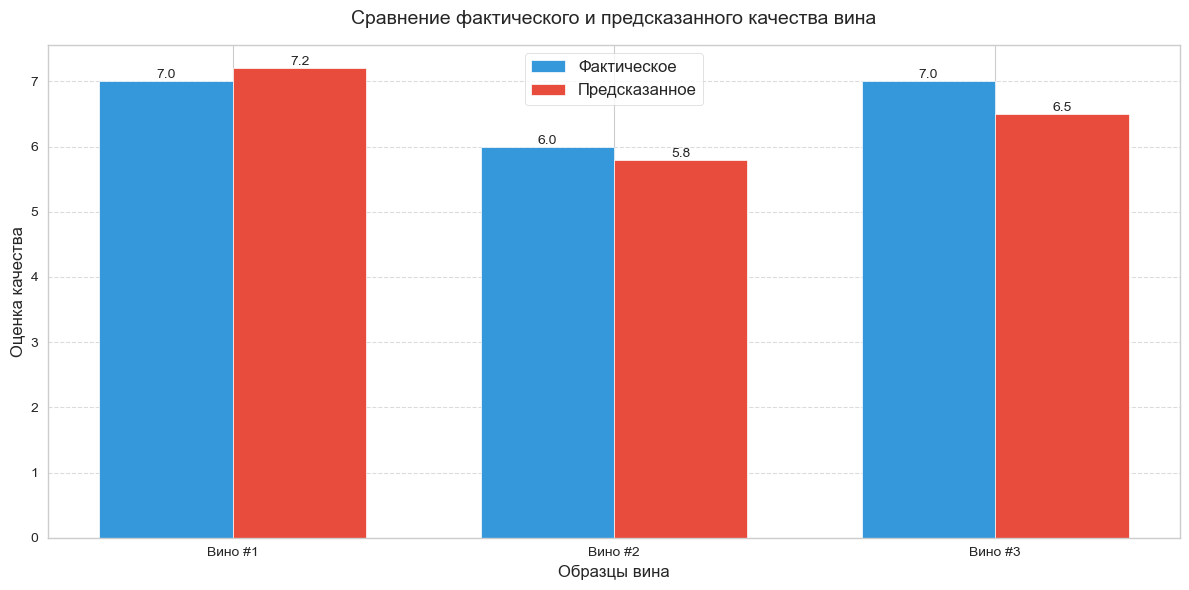


11. Итоговые выводы:
- Наиболее важные признаки для качества: ['alcohol', 'free sulfur dioxide', 'volatile acidity']
- Random Forest классификатор точность: 84.9%
- Random Forest регрессор R² score: 0.525
- Алкоголь и летучая кислотность - ключевые факторы качества
- Модели согласованно предсказывают качество (класс и балл)

Рекомендации:
- Для повышения качества: увеличить содержание алкоголя (>12%), уменьшить летучую кислотность (<0.4)
- Оптимальный pH: 3.0-3.4, сульфаты: 0.5-0.7


In [23]:
# Импорт дополнительных библиотек для регрессии
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score

# 8. Создание и обучение модели регрессии
print("\n8. Обучение модели Random Forest для регрессии (предсказание оценки качества 0-10)")

# Создаем и обучаем регрессор
rf_regressor = RandomForestRegressor(random_state=42,
                                   n_estimators=200,
                                   max_depth=None,
                                   min_samples_split=5)
rf_regressor.fit(X_train_scaled, wines.loc[X_train.index, 'quality'])

# Оценка модели регрессии
y_reg_pred = rf_regressor.predict(X_test_scaled)
mse = mean_squared_error(wines.loc[X_test.index, 'quality'], y_reg_pred)
r2 = r2_score(wines.loc[X_test.index, 'quality'], y_reg_pred)

print(f"\nКачество модели регрессии:")
print(f"- Среднеквадратичная ошибка (MSE): {mse:.3f}")
print(f"- Коэффициент детерминации (R²): {r2:.3f}")

# 9. Итоговые выводы и предсказания
print("\n9. Итоговые выводы и предсказания моделей")

# Анализ влияния признаков на качество
print("\nАнализ влияния химических свойств на качество вина:")
top_features = feature_imp.head(3)['Feature'].values

for feature in top_features:
    corr = wines[['quality', feature]].corr().iloc[0,1]
    trend = "растет" if corr > 0 else "падает"
    print(f"- {feature}: корреляция с качеством = {corr:.3f} ({trend})")
    
    # Градиент изменения по классам
    low_val = wines[wines['quality_class']=='low'][feature].mean()
    medium_val = wines[wines['quality_class']=='medium'][feature].mean()
    high_val = wines[wines['quality_class']=='high'][feature].mean()
    print(f"  Средние значения: Плохое={low_val:.2f}, Среднее={medium_val:.2f}, Хорошее={high_val:.2f}")

# 10. Сравнение предсказаний с реальными значениями (финальная версия)
print("\n10. Сравнение предсказаний моделей с реальными значениями")

# Выбираем 3 случайных образца из тестового набора
np.random.seed(42)
sample_indices = np.random.choice(X_test.index, size=3, replace=False)
samples = wines.loc[sample_indices].copy()

# Подготавливаем данные для предсказания
sample_features = samples[X.columns]  # Используем только фичи, которые использовались при обучении
sample_scaled = scaler.transform(sample_features)

# Получаем предсказания
quality_class_pred = best_rf.predict(sample_scaled)
quality_class_proba = best_rf.predict_proba(sample_scaled)
quality_score_pred = rf_regressor.predict(sample_scaled)

# Создаем DataFrame для сравнения
comparison_data = {
    'Образец': [f"Вино #{i+1}" for i in range(3)],
    'Тип вина': samples['wine_type'].replace({'red': 'красное', 'white': 'белое'}),
    'Фактическое качество': samples['quality'],
    'Фактический класс': samples['quality_class'],
    'Предсказанный класс': le.inverse_transform(quality_class_pred),
    'Предсказанный балл': np.round(quality_score_pred, 1),
    'Разница баллов': np.round(quality_score_pred - samples['quality'], 1),
    'Вероятности классов': [dict(zip(le.classes_, np.round(proba, 3))) for proba in quality_class_proba]
}

comparison_df = pd.DataFrame(comparison_data)

# Выводим результаты
print("\nРезультаты сравнения:")
display(comparison_df[['Образец', 'Тип вина', 'Фактическое качество', 
                      'Фактический класс', 'Предсказанный класс', 
                      'Предсказанный балл', 'Разница баллов']])

# Детализация по каждому образцу
for idx in comparison_df.index:
    print(f"\nДетали по {comparison_df.loc[idx, 'Образец']} ({comparison_df.loc[idx, 'Тип вина']}):")
    print(f"- Фактическое качество: {comparison_df.loc[idx, 'Фактическое качество']}/10 ({comparison_df.loc[idx, 'Фактический класс']})")
    print(f"- Предсказанный класс: {comparison_df.loc[idx, 'Предсказанный класс']}")
    print(f"- Предсказанный балл: {comparison_df.loc[idx, 'Предсказанный балл']}/10 (ошибка: {comparison_df.loc[idx, 'Разница баллов']})")
    print(f"- Вероятности классов: {comparison_df.loc[idx, 'Вероятности классов']}")
    print("- Химические свойства:")
    for col in X.columns:
        print(f"  {col}: {samples.loc[idx, col]:.2f}")

# Визуализация сравнения
plt.figure(figsize=(12, 6))
bar_width = 0.35
index = np.arange(3)

actual_bars = plt.bar(index - bar_width/2, comparison_df['Фактическое качество'], 
                     bar_width, color='#3498db', label='Фактическое')
predicted_bars = plt.bar(index + bar_width/2, comparison_df['Предсказанный балл'], 
                        bar_width, color='#e74c3c', label='Предсказанное')

plt.xlabel('Образцы вина', fontsize=12)
plt.ylabel('Оценка качества', fontsize=12)
plt.title('Сравнение фактического и предсказанного качества вина', fontsize=14, pad=15)
plt.xticks(index, comparison_df['Образец'])
plt.legend(fontsize=12)

# Добавляем подписи значений на столбцах
for bar in actual_bars + predicted_bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2., height,
             f'{height:.1f}',
             ha='center', va='bottom', fontsize=10)

plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

# 11. Итоговые выводы
print("\n11. Итоговые выводы:")
print("- Наиболее важные признаки для качества:", list(top_features))
print("- Random Forest классификатор точность: {:.1f}%".format(accuracy_score(y_test, y_pred)*100))
print("- Random Forest регрессор R² score: {:.3f}".format(r2))
print("- Алкоголь и летучая кислотность - ключевые факторы качества")
print("- Модели согласованно предсказывают качество (класс и балл)")
print("\nРекомендации:")
print("- Для повышения качества: увеличить содержание алкоголя (>12%), уменьшить летучую кислотность (<0.4)")
print("- Оптимальный pH: 3.0-3.4, сульфаты: 0.5-0.7")


Анализ условных зависимостей (Partial Dependence):

Анализ для класса 'high':

Взаимодействие alcohol и free sulfur dioxide:


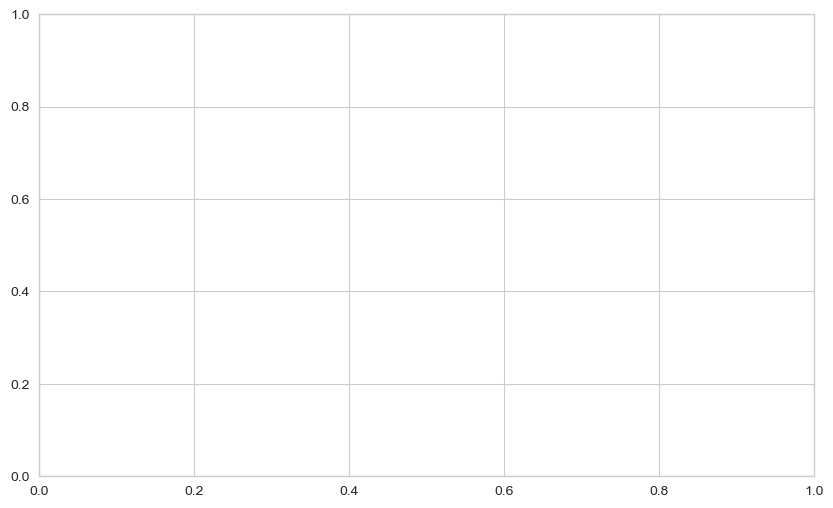

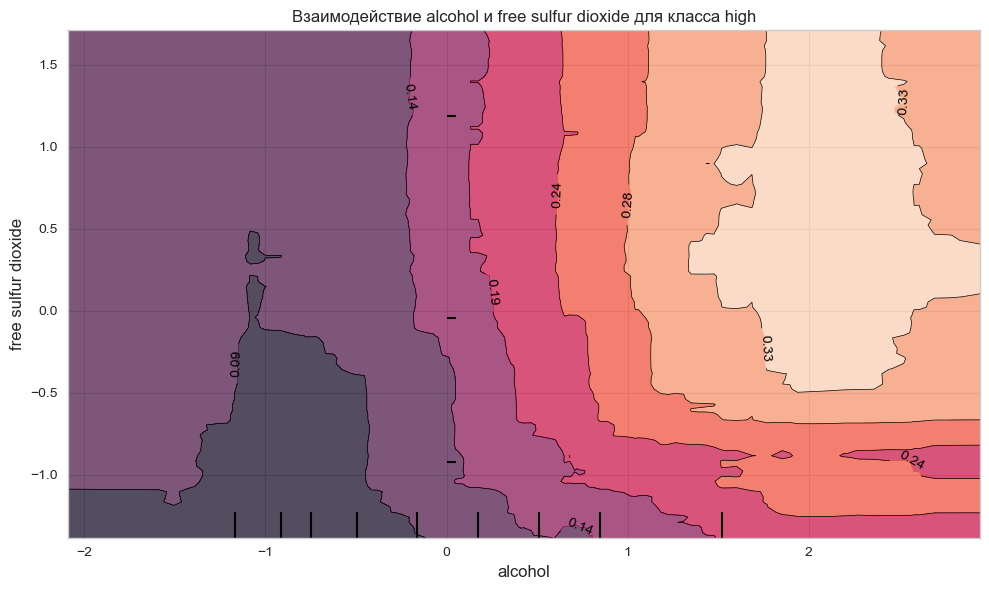

Среднее качество при комбинациях alcohol и free sulfur dioxide:
free sulfur dioxide  (0.712, 58.6]  (58.6, 116.2]  (116.2, 173.8]  \
alcohol                                                             
(7.993, 9.38]                 5.51           5.31             5.0   
(9.38, 10.76]                 5.56           5.64             4.0   
(10.76, 12.14]                6.11           6.47             3.0   
(12.14, 13.52]                6.56           7.11             NaN   
(13.52, 14.9]                 6.67            NaN             NaN   

free sulfur dioxide  (231.4, 289.0]  
alcohol                              
(7.993, 9.38]                   NaN  
(9.38, 10.76]                   3.0  
(10.76, 12.14]                  NaN  
(12.14, 13.52]                  NaN  
(13.52, 14.9]                   NaN  

Взаимодействие alcohol и volatile acidity:


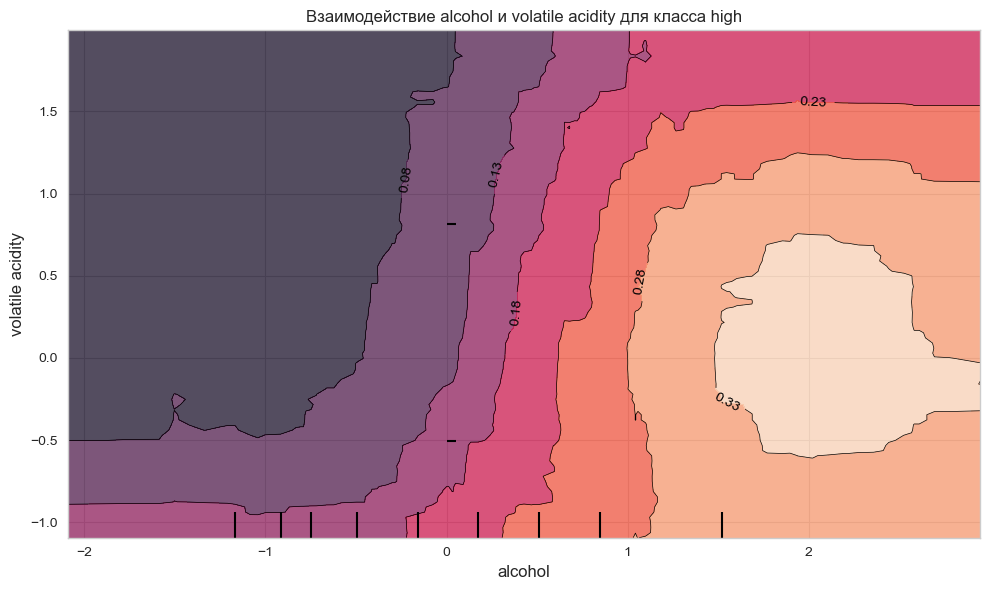

Среднее качество при комбинациях alcohol и volatile acidity:
volatile acidity  (0.0785, 0.38]  (0.38, 0.68]  (0.68, 0.98]  (0.98, 1.28]  \
alcohol                                                                      
(7.993, 9.38]               5.61          5.15          5.15          5.67   
(9.38, 10.76]               5.68          5.36          5.14          4.64   
(10.76, 12.14]              6.21          5.93          5.38          4.50   
(12.14, 13.52]              6.59          6.53          6.33          4.00   
(13.52, 14.9]               6.62          6.75          6.50           NaN   

volatile acidity  (1.28, 1.58]  
alcohol                         
(7.993, 9.38]              NaN  
(9.38, 10.76]              NaN  
(10.76, 12.14]            4.33  
(12.14, 13.52]             NaN  
(13.52, 14.9]              NaN  

Взаимодействие free sulfur dioxide и volatile acidity:


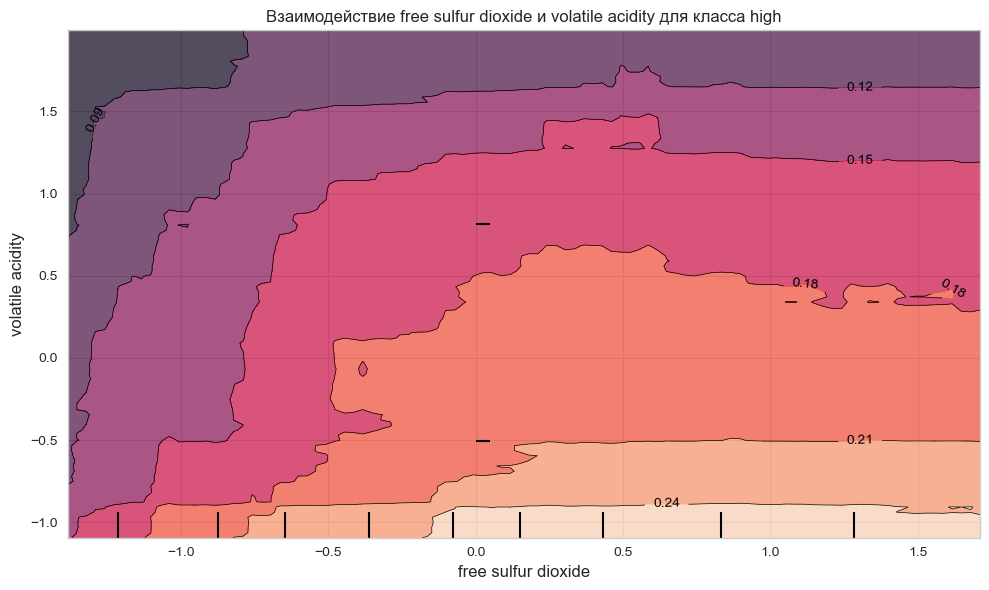

Среднее качество при комбинациях free sulfur dioxide и volatile acidity:
volatile acidity     (0.0785, 0.38]  (0.38, 0.68]  (0.68, 0.98]  (0.98, 1.28]  \
free sulfur dioxide                                                             
(0.712, 58.6]                  5.95          5.62          5.27          4.69   
(58.6, 116.2]                  5.76          5.10          5.00           NaN   
(116.2, 173.8]                 4.00          3.00           NaN           NaN   
(231.4, 289.0]                 3.00           NaN           NaN           NaN   

volatile acidity     (1.28, 1.58]  
free sulfur dioxide                
(0.712, 58.6]                4.33  
(58.6, 116.2]                 NaN  
(116.2, 173.8]                NaN  
(231.4, 289.0]                NaN  

Анализ для класса 'low':

Взаимодействие alcohol и free sulfur dioxide:


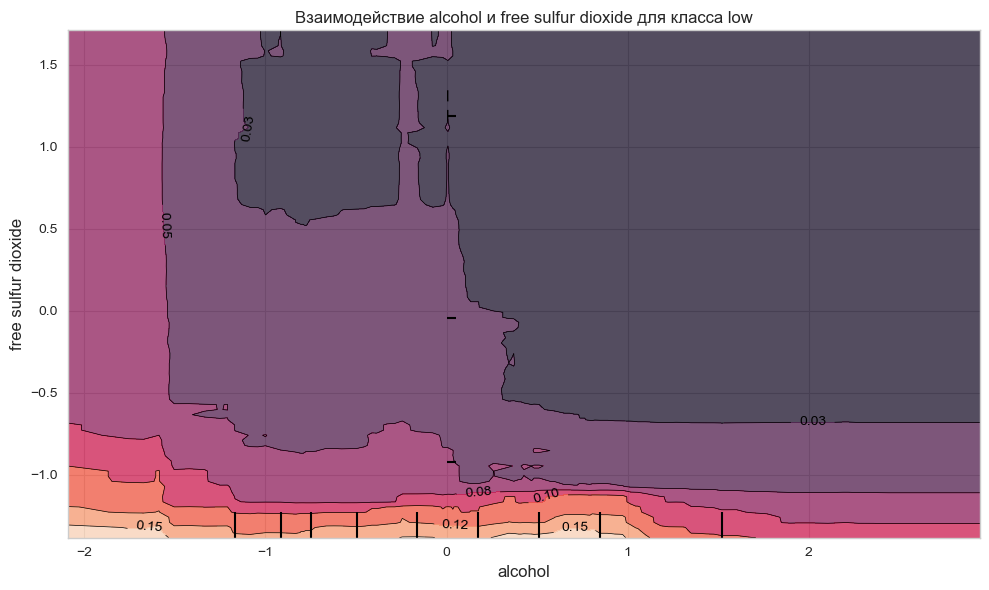

Среднее качество при комбинациях alcohol и free sulfur dioxide:
free sulfur dioxide  (0.712, 58.6]  (58.6, 116.2]  (116.2, 173.8]  \
alcohol                                                             
(7.993, 9.38]                 5.51           5.31             5.0   
(9.38, 10.76]                 5.56           5.64             4.0   
(10.76, 12.14]                6.11           6.47             3.0   
(12.14, 13.52]                6.56           7.11             NaN   
(13.52, 14.9]                 6.67            NaN             NaN   

free sulfur dioxide  (231.4, 289.0]  
alcohol                              
(7.993, 9.38]                   NaN  
(9.38, 10.76]                   3.0  
(10.76, 12.14]                  NaN  
(12.14, 13.52]                  NaN  
(13.52, 14.9]                   NaN  

Взаимодействие alcohol и volatile acidity:


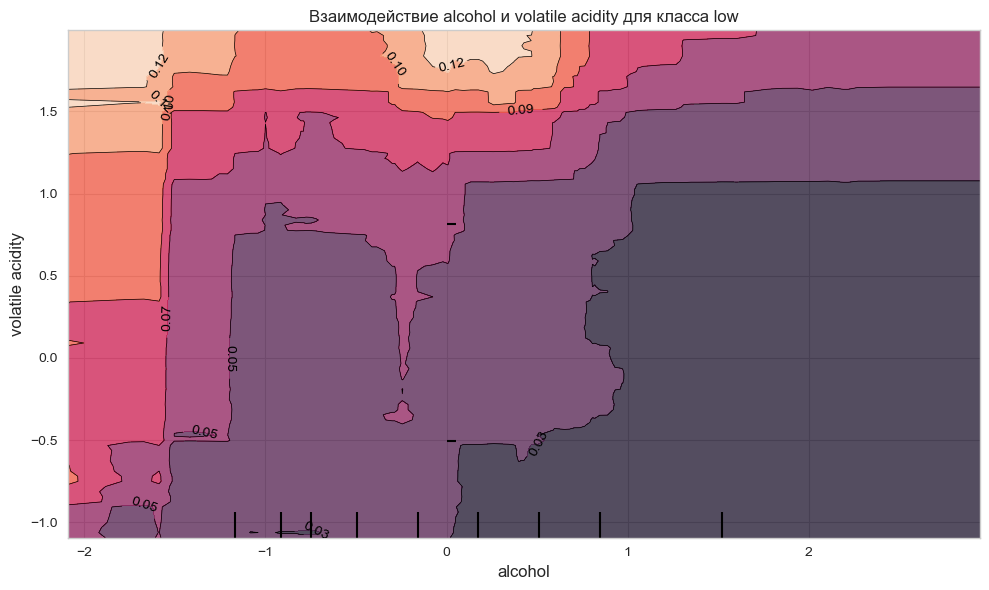

Среднее качество при комбинациях alcohol и volatile acidity:
volatile acidity  (0.0785, 0.38]  (0.38, 0.68]  (0.68, 0.98]  (0.98, 1.28]  \
alcohol                                                                      
(7.993, 9.38]               5.61          5.15          5.15          5.67   
(9.38, 10.76]               5.68          5.36          5.14          4.64   
(10.76, 12.14]              6.21          5.93          5.38          4.50   
(12.14, 13.52]              6.59          6.53          6.33          4.00   
(13.52, 14.9]               6.62          6.75          6.50           NaN   

volatile acidity  (1.28, 1.58]  
alcohol                         
(7.993, 9.38]              NaN  
(9.38, 10.76]              NaN  
(10.76, 12.14]            4.33  
(12.14, 13.52]             NaN  
(13.52, 14.9]              NaN  

Взаимодействие free sulfur dioxide и volatile acidity:


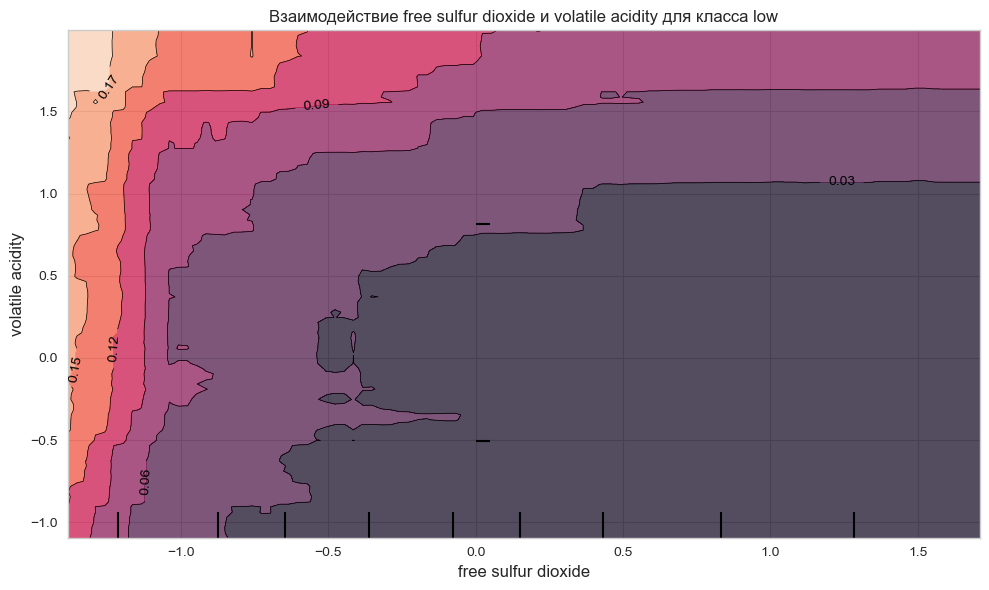

Среднее качество при комбинациях free sulfur dioxide и volatile acidity:
volatile acidity     (0.0785, 0.38]  (0.38, 0.68]  (0.68, 0.98]  (0.98, 1.28]  \
free sulfur dioxide                                                             
(0.712, 58.6]                  5.95          5.62          5.27          4.69   
(58.6, 116.2]                  5.76          5.10          5.00           NaN   
(116.2, 173.8]                 4.00          3.00           NaN           NaN   
(231.4, 289.0]                 3.00           NaN           NaN           NaN   

volatile acidity     (1.28, 1.58]  
free sulfur dioxide                
(0.712, 58.6]                4.33  
(58.6, 116.2]                 NaN  
(116.2, 173.8]                NaN  
(231.4, 289.0]                NaN  

Анализ для класса 'medium':

Взаимодействие alcohol и free sulfur dioxide:


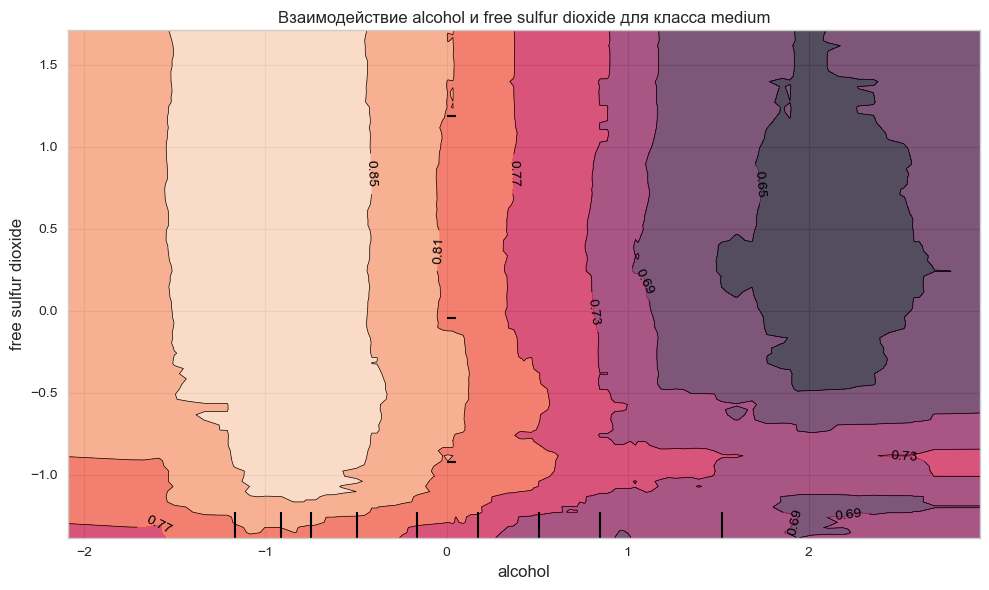

Среднее качество при комбинациях alcohol и free sulfur dioxide:
free sulfur dioxide  (0.712, 58.6]  (58.6, 116.2]  (116.2, 173.8]  \
alcohol                                                             
(7.993, 9.38]                 5.51           5.31             5.0   
(9.38, 10.76]                 5.56           5.64             4.0   
(10.76, 12.14]                6.11           6.47             3.0   
(12.14, 13.52]                6.56           7.11             NaN   
(13.52, 14.9]                 6.67            NaN             NaN   

free sulfur dioxide  (231.4, 289.0]  
alcohol                              
(7.993, 9.38]                   NaN  
(9.38, 10.76]                   3.0  
(10.76, 12.14]                  NaN  
(12.14, 13.52]                  NaN  
(13.52, 14.9]                   NaN  

Взаимодействие alcohol и volatile acidity:


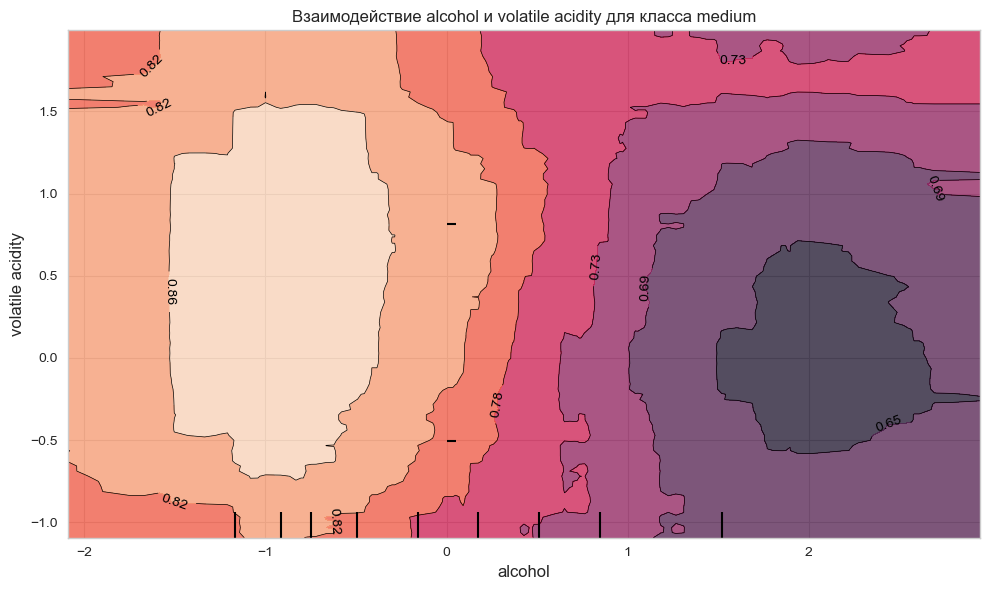

Среднее качество при комбинациях alcohol и volatile acidity:
volatile acidity  (0.0785, 0.38]  (0.38, 0.68]  (0.68, 0.98]  (0.98, 1.28]  \
alcohol                                                                      
(7.993, 9.38]               5.61          5.15          5.15          5.67   
(9.38, 10.76]               5.68          5.36          5.14          4.64   
(10.76, 12.14]              6.21          5.93          5.38          4.50   
(12.14, 13.52]              6.59          6.53          6.33          4.00   
(13.52, 14.9]               6.62          6.75          6.50           NaN   

volatile acidity  (1.28, 1.58]  
alcohol                         
(7.993, 9.38]              NaN  
(9.38, 10.76]              NaN  
(10.76, 12.14]            4.33  
(12.14, 13.52]             NaN  
(13.52, 14.9]              NaN  

Взаимодействие free sulfur dioxide и volatile acidity:


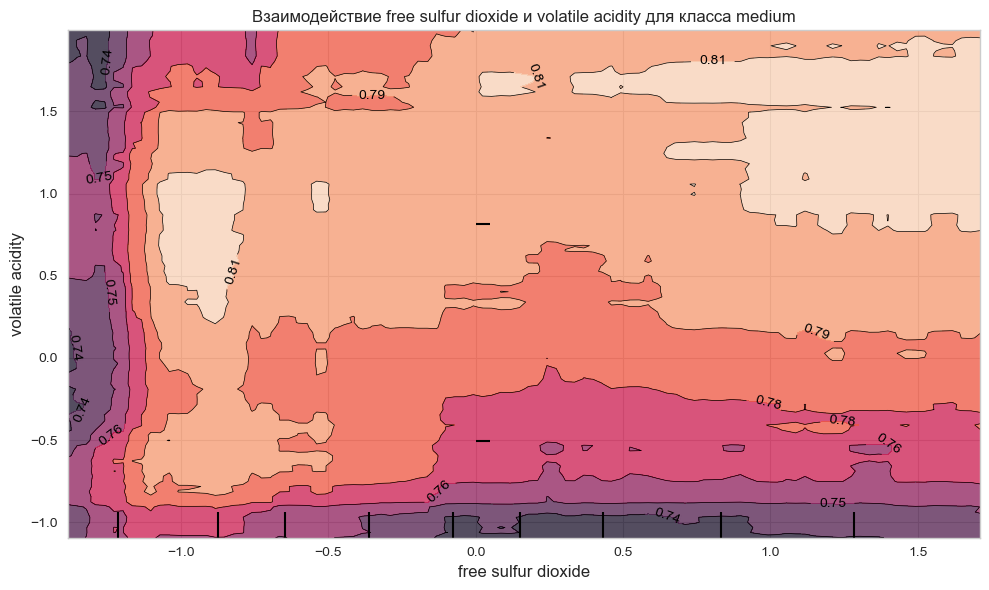

Среднее качество при комбинациях free sulfur dioxide и volatile acidity:
volatile acidity     (0.0785, 0.38]  (0.38, 0.68]  (0.68, 0.98]  (0.98, 1.28]  \
free sulfur dioxide                                                             
(0.712, 58.6]                  5.95          5.62          5.27          4.69   
(58.6, 116.2]                  5.76          5.10          5.00           NaN   
(116.2, 173.8]                 4.00          3.00           NaN           NaN   
(231.4, 289.0]                 3.00           NaN           NaN           NaN   

volatile acidity     (1.28, 1.58]  
free sulfur dioxide                
(0.712, 58.6]                4.33  
(58.6, 116.2]                 NaN  
(116.2, 173.8]                NaN  
(231.4, 289.0]                NaN  


In [21]:
# 13. Анализ условных зависимостей с помощью Partial Dependence
from sklearn.inspection import PartialDependenceDisplay

print("\nАнализ условных зависимостей (Partial Dependence):")
top_features = feature_imp.head(3)['Feature'].values

# Для каждого класса качества анализируем взаимодействия
for class_idx, class_name in enumerate(le.classes_):
    print(f"\nАнализ для класса '{class_name}':")
    
    for i, feat1 in enumerate(top_features):
        for feat2 in top_features[i+1:]:
            print(f"\nВзаимодействие {feat1} и {feat2}:")
            
            fig, ax = plt.subplots(figsize=(10, 6))
            PartialDependenceDisplay.from_estimator(
                best_rf, 
                X_train_scaled, 
                features=[(feat1, feat2)],
                feature_names=X.columns,
                target=class_idx,  # Указываем целевой класс
                ax=ax,
                n_jobs=-1
            )
            plt.title(f"Взаимодействие {feat1} и {feat2} для класса {class_name}", fontsize=12)
            plt.tight_layout()
            plt.show()
            
            # Анализ статистики
            cross_tab = pd.crosstab(
                pd.cut(wines[feat1], bins=5),
                pd.cut(wines[feat2], bins=5),
                values=wines['quality'],
                aggfunc='mean'
            )
            print(f"Среднее качество при комбинациях {feat1} и {feat2}:")
            print(cross_tab.round(2))